# SmartShip AI — Late-Delivery Risk Prediction
### Machine Learning Final Project | Olist Brazilian E-Commerce

**Project objective.** Develop and evaluate a machine-learning system that identifies orders at elevated risk of arriving after their estimated delivery date. The accompanying Streamlit prototype supports order-level risk assessment and historical seller-performance monitoring.

**Approach.** Relational data integration → data quality review → exploratory analysis → leakage-aware preprocessing → baseline and model comparison → cross-validation and tuning → validation-based threshold selection → held-out test evaluation → business recommendations and application artifacts.

**Scope.** Results describe historical Brazilian e-commerce orders. Predictions are intended to support human review, not to establish fault or to represent calibrated delivery-delay probabilities.

**Data source:** [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).

## 0. Environment and data source

Load the original Olist CSV tables from the project's `data/` directory. This section also checks the project path and reports the sizes of the source tables.

**Reproducibility:** Run this notebook from the `SmartShip-AI` project directory, with the original CSVs stored under `data/`. Use **Restart & Run All** to regenerate outputs. The dataset itself should be linked—not committed as large raw files—to the GitHub repository.

In [1]:
from pathlib import Path

# Run the notebook with the SmartShip-AI project folder as its working directory.
# It must contain data/ with the original Olist CSV files.
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "olist_orders_dataset.csv").exists():
    candidate = PROJECT_DIR / "SmartShip-AI"
    if (candidate / "data" / "olist_orders_dataset.csv").exists():
        PROJECT_DIR = candidate
    else:
        raise FileNotFoundError(
            "Olist CSV files not found. Open the SmartShip-AI folder in VS Code "
            "and run this notebook with that folder as the working directory."
        )

import os
os.chdir(PROJECT_DIR)
print("Project directory:", PROJECT_DIR.resolve())
print("Data CSV files:", len(list((PROJECT_DIR / "data").glob("*.csv"))))

Project directory: C:\Users\Administrator\Desktop\SmartShip-AI
Data CSV files: 14


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
pd.set_option("display.max_columns", None)
print("Libraries loaded")

Libraries loaded


In [3]:
import os

DATA_DIR = "data"

orders      = pd.read_csv(f"{DATA_DIR}/olist_orders_dataset.csv")
items       = pd.read_csv(f"{DATA_DIR}/olist_order_items_dataset.csv")
customers   = pd.read_csv(f"{DATA_DIR}/olist_customers_dataset.csv")
sellers     = pd.read_csv(f"{DATA_DIR}/olist_sellers_dataset.csv")
products    = pd.read_csv(f"{DATA_DIR}/olist_products_dataset.csv")
reviews     = pd.read_csv(f"{DATA_DIR}/olist_order_reviews_dataset.csv")
payments    = pd.read_csv(f"{DATA_DIR}/olist_order_payments_dataset.csv")
geo         = pd.read_csv(f"{DATA_DIR}/olist_geolocation_dataset.csv")
categories  = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")

tables = {"orders": orders, "items": items, "customers": customers,
          "sellers": sellers, "products": products, "reviews": reviews,
          "payments": payments, "geo": geo, "categories": categories}

for name, df in tables.items():
    print(f"{name:12s} -> {df.shape}")

orders       -> (99441, 8)
items        -> (112650, 7)
customers    -> (99441, 5)
sellers      -> (3095, 4)
products     -> (32951, 9)
reviews      -> (99224, 7)
payments     -> (103886, 5)
geo          -> (1000163, 5)
categories   -> (71, 2)


## 1. Business problem, prediction target and evaluation priorities

**Problem.** Late deliveries can undermine customer trust and create additional service costs for an online marketplace. Operations teams need an early warning so that they can prioritize carrier monitoring and customer communication.

**Prediction task.** Binary classification at purchase time, using order and shipping information available then.

**Target definition:** `is_late = 1` when `order_delivered_customer_date > order_estimated_delivery_date`; otherwise `is_late = 0`. The target is derived from historical delivery outcomes, but actual delivery timestamps are **not** used as predictive features.

**Business evaluation.** Prioritize **recall** for the late-delivery class to identify more delayed orders, while monitoring **precision** (false-alert workload), **F1**, and **PR-AUC** (appropriate for class imbalance). A selected alert threshold is a decision rule, not a guarantee of future performance.

**Dataset scope.** Train and evaluate on orders marked delivered with the dates required to construct the target. This does not evaluate canceled or never-delivered orders.

Delivered orders: 96470
is_late
0    88644
1     7826
Name: count, dtype: int64
is_late
0    0.9189
1    0.0811
Name: proportion, dtype: float64


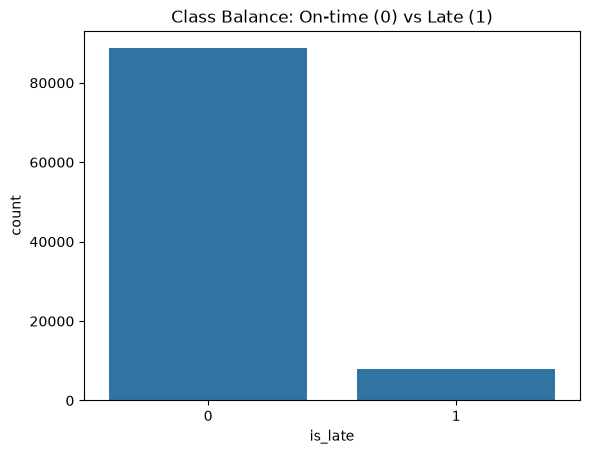

In [4]:
for c in ["order_purchase_timestamp", "order_approved_at",
          "order_delivered_carrier_date", "order_delivered_customer_date",
          "order_estimated_delivery_date"]:
    orders[c] = pd.to_datetime(orders[c])
delivered = orders[orders["order_status"] == "delivered"].dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
).copy()
delivered["is_late"] = (delivered["order_delivered_customer_date"] >
                        delivered["order_estimated_delivery_date"]).astype(int)

print("Delivered orders:", len(delivered))
print(delivered["is_late"].value_counts())
print(delivered["is_late"].value_counts(normalize=True).round(4))

sns.countplot(x="is_late", data=delivered)
plt.title("Class Balance: On-time (0) vs Late (1)")
plt.show()

In [5]:
for name, df in tables.items():
    print(f"\n===== {name} {df.shape} =====")
    info = pd.DataFrame({
        "dtype": df.dtypes,
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2)
    })
    print(info[info["missing"] > 0] if info["missing"].sum() > 0 else "No missing values")


===== orders (99441, 8) =====
                                        dtype  missing  missing_%
order_approved_at              datetime64[us]      160       0.16
order_delivered_carrier_date   datetime64[us]     1783       1.79
order_delivered_customer_date  datetime64[us]     2965       2.98

===== items (112650, 7) =====
No missing values

===== customers (99441, 5) =====
No missing values

===== sellers (3095, 4) =====
No missing values

===== products (32951, 9) =====
                              dtype  missing  missing_%
product_category_name           str      610       1.85
product_name_lenght         float64      610       1.85
product_description_lenght  float64      610       1.85
product_photos_qty          float64      610       1.85
product_weight_g            float64        2       0.01
product_length_cm           float64        2       0.01
product_height_cm           float64        2       0.01
product_width_cm            float64        2       0.01

===== reviews (99

## 2. Relational joins and feature engineering

The dataset is assembled at the **order level** by joining order, customer, item, seller, product, category and geographical information.

- Aggregate item price and freight to the order level and count items.
- For orders associated with more than one product or seller, use the first item's seller/product for representative attributes; this simplification is a limitation of the model inputs.
- Derive purchase timing, estimated delivery days, freight ratio, product volume, same-state shipping and straight-line seller-to-customer distance using ZIP-prefix geographical centroids and the Haversine formula.
- Exclude actual delivery outcomes from the predictor columns to avoid direct target leakage.

In [6]:
df = delivered[["order_id", "customer_id", "order_purchase_timestamp",
                "order_estimated_delivery_date", "is_late"]].copy()

df = df.merge(customers[["customer_id", "customer_state", "customer_zip_code_prefix"]],
              on="customer_id", how="left")


order_items = items.groupby("order_id").agg(
    price=("price", "sum"),
    freight_value=("freight_value", "sum"),
    n_items=("order_item_id", "count"),
    n_sellers=("seller_id", "nunique"),
    seller_id=("seller_id", "first"),
    product_id=("product_id", "first")
).reset_index()

df = df.merge(order_items, on="order_id", how="left")

df = df.merge(sellers[["seller_id", "seller_state", "seller_zip_code_prefix"]],
              on="seller_id", how="left")
df = df.merge(products[["product_id", "product_category_name", "product_weight_g",
                        "product_length_cm", "product_height_cm", "product_width_cm"]],
              on="product_id", how="left")

print(df.shape)
df.head()

(96470, 20)


,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,is_late,customer_state,customer_zip_code_prefix,price,freight_value,n_items,n_sellers,seller_id,product_id,seller_state,seller_zip_code_prefix,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,0,SP,3149,29.99,8.72,1,1,3504c0cb71d7fa48d967e0e4c94d59d9,87285b34884572647811a353c7ac498a,SP,9350,utilidades_domesticas,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,0,BA,47813,118.70,22.76,1,1,289cdb325fb7e7f891c38608bf9e0962,595fac2a385ac33a80bd5114aec74eb8,SP,31570,perfumaria,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,0,GO,75265,159.90,19.22,1,1,4869f7a5dfa277a7dca6462dcf3b52b2,aa4383b373c6aca5d8797843e5594415,SP,14840,automotivo,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,0,RN,59296,45.00,27.20,1,1,66922902710d126a0e7d26b0e3805106,d0b61bfb1de832b15ba9d266ca96e5b0,MG,31842,pet_shop,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,0,SP,9195,19.90,8.72,1,1,2c9e548be18521d1c43cde1c582c6de8,65266b2da20d04dbe00c5c2d3bb7859e,SP,8752,papelaria,250.0,51.0,15.0,15.0


In [7]:
geo_agg = geo.groupby("geolocation_zip_code_prefix").agg(
    lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean")).reset_index()

df = df.merge(geo_agg.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix",
                                      "lat": "cust_lat", "lng": "cust_lng"}),
              on="customer_zip_code_prefix", how="left")
df = df.merge(geo_agg.rename(columns={"geolocation_zip_code_prefix": "seller_zip_code_prefix",
                                      "lat": "sell_lat", "lng": "sell_lng"}),
              on="seller_zip_code_prefix", how="left")

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df["sell_lat"], df["sell_lng"], df["cust_lat"], df["cust_lng"])

df["purchase_month"] = df["order_purchase_timestamp"].dt.month
df["purchase_dow"]   = df["order_purchase_timestamp"].dt.dayofweek
df["purchase_hour"]  = df["order_purchase_timestamp"].dt.hour
df["estimated_days"] = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]).dt.days

df["same_state"]    = (df["customer_state"] == df["seller_state"]).astype(int)
df["freight_ratio"] = df["freight_value"] / (df["price"] + 1)
df["volume_cm3"]    = df["product_length_cm"] * df["product_height_cm"] * df["product_width_cm"]

df = df.merge(categories, on="product_category_name", how="left")

print(df.shape)
print(df[["distance_km", "estimated_days", "freight_ratio", "volume_cm3"]].describe().round(2))
print(df.isna().sum()[df.isna().sum() > 0])

print("Orders with distance > 4000 km:",
      (df["distance_km"] > 4000).sum())

print("Orders with multiple sellers:",
      (df["n_sellers"] > 1).sum())

print("Missing distance:",
      df["distance_km"].isna().sum())


(96470, 33)
       distance_km  estimated_days  freight_ratio  volume_cm3
count     95992.00        96470.00       96470.00    96454.00
mean        600.76           23.37           0.30    15158.64
std         593.71            8.76           0.28    23299.04
min           0.00            2.00           0.00      168.00
25%         185.93           18.00           0.13     2816.00
50%         433.87           23.00           0.22     6384.00
75%         798.55           28.00           0.37    18216.00
max        8677.91          155.00           9.85   296208.00
product_category_name            1359
product_weight_g                   16
product_length_cm                  16
product_height_cm                  16
product_width_cm                   16
cust_lat                          264
cust_lng                          264
sell_lat                          215
sell_lng                          215
distance_km                       478
volume_cm3                         16
product_cate

## 3. Exploratory data analysis (EDA)

The following visualizations examine delivery outcomes by customer state, shipping distance, purchase month and same-state shipping. Further distribution plots and a correlation heatmap examine the numeric features. Interpretations are **descriptive associations** within the historical data—not causal effects.

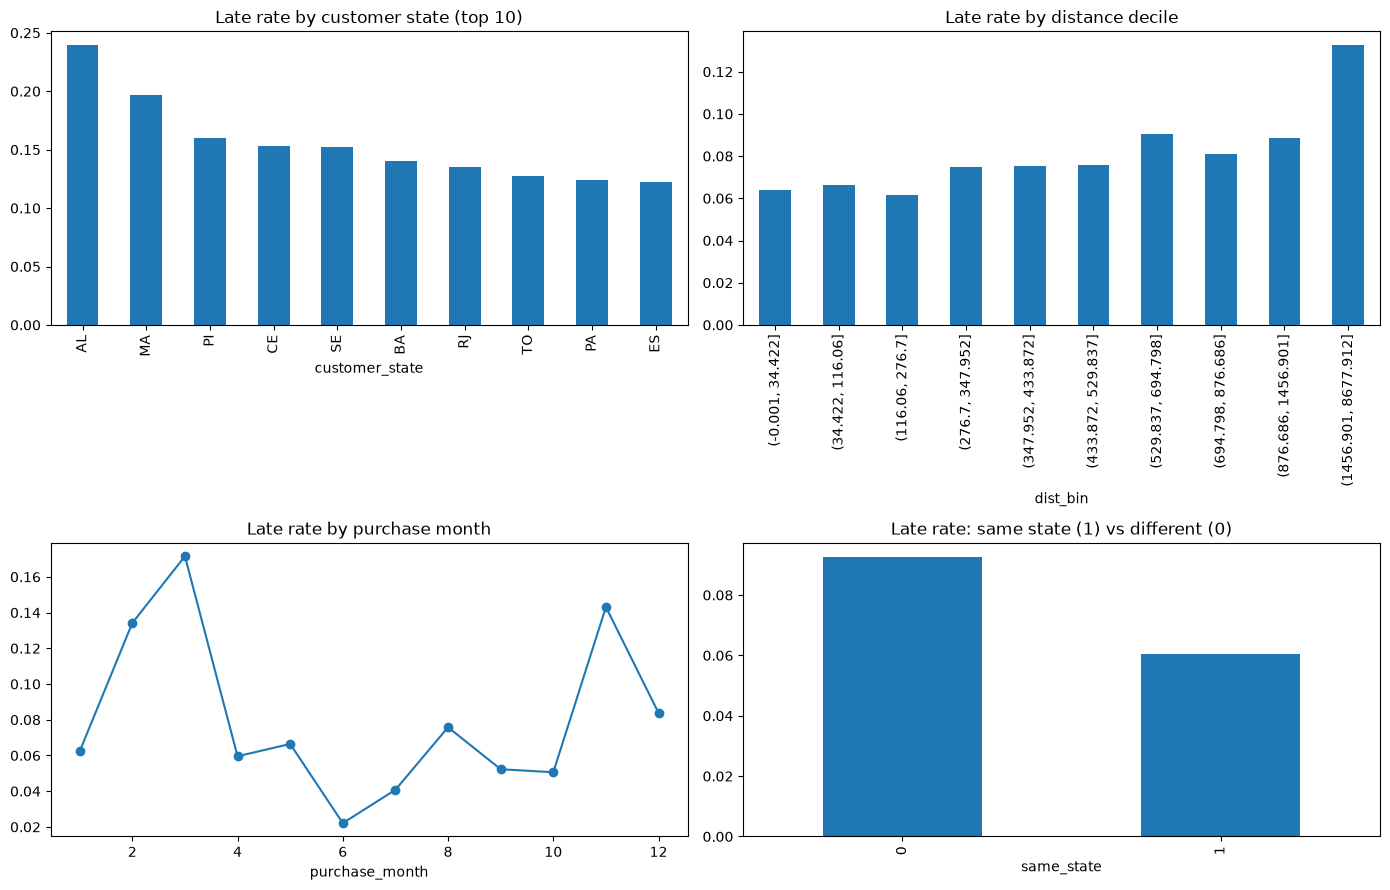

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

df.groupby("customer_state")["is_late"].mean().sort_values(ascending=False).head(10).plot(
    kind="bar", ax=axes[0, 0], title="Late rate by customer state (top 10)")

df["dist_bin"] = pd.qcut(df["distance_km"], 10, duplicates="drop")
df.groupby("dist_bin")["is_late"].mean().plot(
    kind="bar", ax=axes[0, 1], title="Late rate by distance decile")

df.groupby("purchase_month")["is_late"].mean().plot(
    marker="o", ax=axes[1, 0], title="Late rate by purchase month")

df.groupby("same_state")["is_late"].mean().plot(
    kind="bar", ax=axes[1, 1], title="Late rate: same state (1) vs different (0)")

plt.tight_layout()
plt.show()

### 3.1 Delivery-pattern findings

1. **Customer geography:** Historical late-delivery rates differ by state; the exploratory results include approximately 24% for AL and 20% for MA versus roughly 8% across delivered orders.
2. **Distance:** The observed late rate generally increases with shipping distance, reaching approximately 13.5% in the farthest distance group.
3. **Seasonality:** The observed late rate is higher in March (around 17%) and November (around 15.5%), and lower in June (around 3%).
4. **State boundaries:** Cross-state shipping is associated with a higher observed late rate (approximately 9%) than same-state shipping (approximately 6.5%).

These figures describe the exploratory dataset; the charts provide the underlying comparisons.

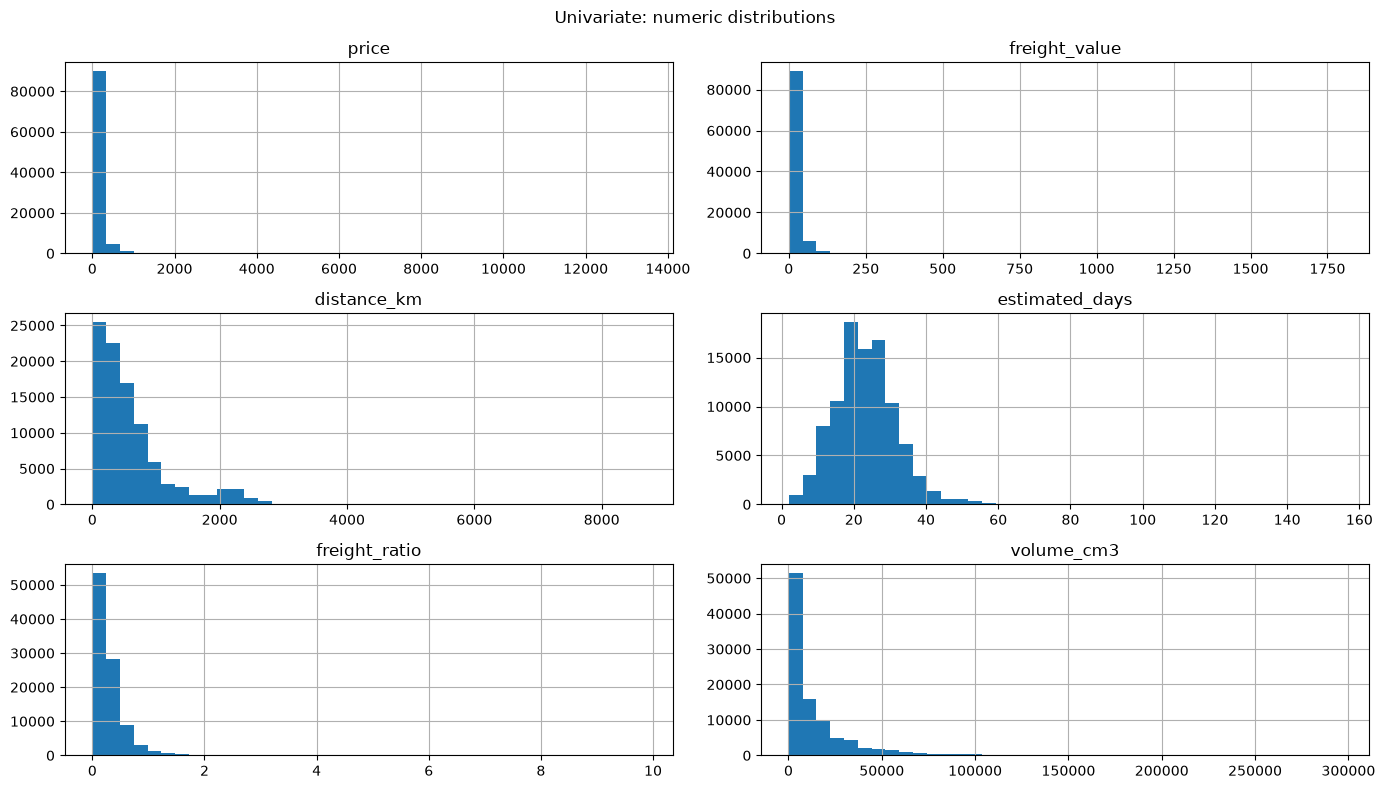

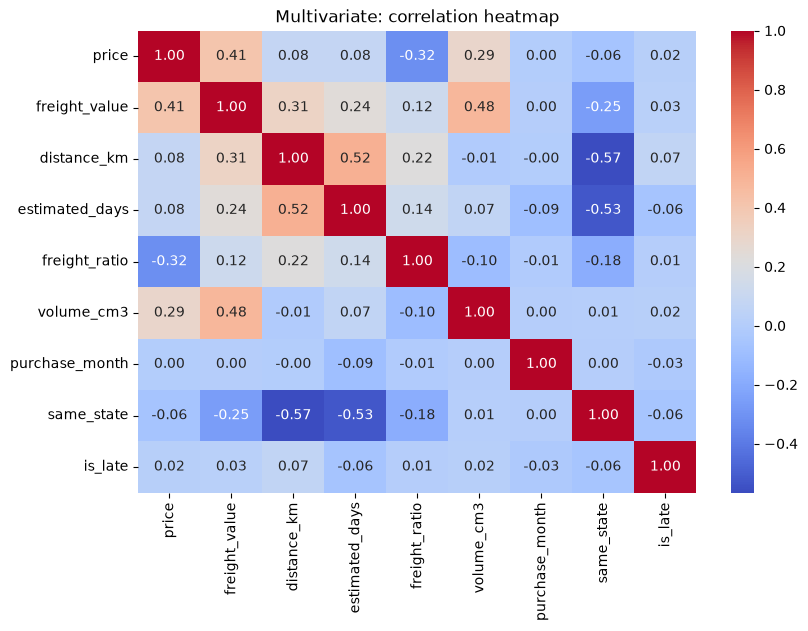

In [9]:
num_cols = ["price", "freight_value", "distance_km", "estimated_days", "freight_ratio", "volume_cm3"]

df[num_cols].hist(bins=40, figsize=(14, 8))
plt.suptitle("Univariate: numeric distributions")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
sns.heatmap(df[num_cols + ["purchase_month", "same_state", "is_late"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Multivariate: correlation heatmap")
plt.show()

### 3.2 Feature distributions and correlations

5. **Skewness:** Several continuous predictors—including price, freight, distance, freight ratio and product volume—are right-skewed. Their preprocessing branch uses `log1p` followed by scaling.
6. **Correlation:** The correlation heatmap indicates a positive association between distance and estimated delivery days (approximately 0.52). The absence of one strong linear relationship with lateness motivates comparison with nonlinear models; correlation alone cannot establish predictive utility.

## 4. Preprocessing and train/validation/test split

Split observations into **training, validation and held-out test sets** using a fixed seed and stratification. The training set is used for cross-validation and model tuning; the validation set is used to select the decision threshold; the test set is reserved for final assessment.

Build scikit-learn Pipelines that fit imputation, numerical transformations/scaling and categorical encoding **within training folds**, rather than fitting these transformations on all records before evaluation.

**Generalization limitation:** The random stratified split estimates performance on similar historical observations, not performance on a future time period. The dataset's historical distribution may differ from today's operations.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

num_features = ["price", "freight_value", "n_items", "product_weight_g", "distance_km",
                "estimated_days", "freight_ratio", "volume_cm3",
                "purchase_month", "purchase_dow", "purchase_hour", "same_state"]
cat_features = ["customer_state", "seller_state", "product_category_name_english"]

X = df[num_features + cat_features]
y = df["is_late"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_valid.shape)
print("Test set:", X_test.shape)

log_features = [
    "price", "freight_value", "n_items",
    "product_weight_g", "distance_km",
    "freight_ratio", "volume_cm3"
]

other_num_features = [
    "estimated_days", "purchase_month",
    "purchase_dow", "purchase_hour", "same_state"
]

log_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, validate=False)),
    ("scaler", StandardScaler())
])

other_num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant", fill_value="unknown"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore", min_frequency=50
    ))
])

preprocessor = ColumnTransformer([
    ("log_num", log_pipe, log_features),
    ("other_num", other_num_pipe, other_num_features),
    ("cat", cat_pipe, cat_features)
])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(
    "Late rate train:", round(y_train.mean(), 4),
    "| test:", round(y_test.mean(), 4)
)


Training set: (61740, 15)
Validation set: (15436, 15)
Test set: (19294, 15)
Train: (61740, 15) | Test: (19294, 15)
Late rate train: 0.0811 | test: 0.0811


## 5. Baseline and model comparison

Compare a **majority-class DummyClassifier** with three classification algorithms: **Logistic Regression, Random Forest and HistGradientBoosting**. Use stratified five-fold cross-validation on the training split and compare recall, precision, F1 and average precision (**PR-AUC**).

Since relatively few orders are late, accuracy alone could conceal missed delays. Cross-validation results below are the output of the actual training code.

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score

cat_pipe_dense = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False))
])

preprocessor_dense = ColumnTransformer([
    ("log_num", log_pipe, log_features),
    ("other_num", other_num_pipe, other_num_features),
    ("cat", cat_pipe_dense, cat_features)
])


models = {
    "Baseline (Dummy)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        min_samples_leaf=5,
        n_jobs=-1,
        random_state=42
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=42
    )
}
dense_models = {"Gradient Boosting"}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"recall": "recall", "precision": make_scorer(precision_score, zero_division=0), "f1": make_scorer(f1_score, zero_division=0), "pr_auc": "average_precision"}

results = []
for name, model in models.items():
    prep = preprocessor_dense if name in dense_models else preprocessor
    pipe = Pipeline([("prep", prep), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    results.append({"model": name, **{k: scores[f"test_{k}"].mean().round(4) for k in scoring}})
    print(name, "done")

results_df = pd.DataFrame(results).sort_values("pr_auc", ascending=False)
results_df



Baseline (Dummy) done
Logistic Regression done
Random Forest done
Gradient Boosting done


,model,recall,precision,f1,pr_auc
3,Gradient Boosting,0.6624,0.1990,0.3060,0.2795
2,Random Forest,0.3416,0.3254,0.3331,0.2735
1,Logistic Regression,0.6416,0.1445,0.2359,0.1812
0,Baseline (Dummy),0.0000,0.0000,0.0000,0.0811


## 6. Hyperparameter tuning and alert-threshold selection

Use `RandomizedSearchCV` with three-fold stratified cross-validation to tune **HistGradientBoostingClassifier** on the training split, optimizing PR-AUC.

Then generate prediction scores on the separate **validation split**. Select the threshold that maximizes precision among thresholds achieving at least **70% validation recall**. The observed threshold is approximately **0.4801**.

The final **test set is not used to choose the threshold**. Validation and test recall can differ.

In [12]:
from sklearn.model_selection import RandomizedSearchCV

pipe = Pipeline([("prep", preprocessor_dense),
                 ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=42))])

param_dist = {
    "model__learning_rate": [0.03, 0.05, 0.1, 0.15],
    "model__max_iter": [150, 250, 400],
    "model__max_depth": [None, 4, 6, 8],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0, 5.0],
}

search = RandomizedSearchCV(
    pipe, param_dist, n_iter=12, scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42, n_jobs=1, verbose=1)

search.fit(X_train, y_train)

print("Best PR-AUC (CV):", round(search.best_score_, 4))
print("Best params:", search.best_params_)
best_model = search.best_estimator_

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best PR-AUC (CV): 0.2794
Best params: {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 31, 'model__max_iter': 250, 'model__max_depth': None, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.0}


In [13]:

from sklearn.metrics import precision_recall_curve
import numpy as np

# Best tuned model
best_model = search.best_estimator_

# Predict on validation set only
valid_proba = best_model.predict_proba(X_valid)[:, 1]

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_valid, valid_proba
)

# Select threshold with at least 70% recall
target_recall = 0.70

valid_idx = np.where(recall[:-1] >= target_recall)[0]

if len(valid_idx) == 0:
    raise ValueError("No threshold achieves target recall.")

best_idx = valid_idx[np.argmax(precision[:-1][valid_idx])]
best_thr = float(thresholds[best_idx])

print("Selected threshold:", round(best_thr, 4))
print("Validation recall:", round(recall[best_idx], 4))
print("Validation precision:", round(precision[best_idx], 4))


Selected threshold: 0.4801
Validation recall: 0.7013
Validation precision: 0.1903


## 7. Final assessment on the held-out test set

Apply the tuned model and validation-selected threshold to the untouched test set. Report classification metrics, the confusion matrix and the distribution of false alarms and missed delays. This is the final performance estimate for the **historical holdout**, not a claim of guaranteed future accuracy.

Accuracy: 0.7302
Precision: 0.1852
Recall: 0.6843
F1-score: 0.2915
ROC-AUC: 0.7834
PR-AUC: 0.2828

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.73      0.83     17729
           1       0.19      0.68      0.29      1565

    accuracy                           0.73     19294
   macro avg       0.57      0.71      0.56     19294
weighted avg       0.90      0.73      0.79     19294



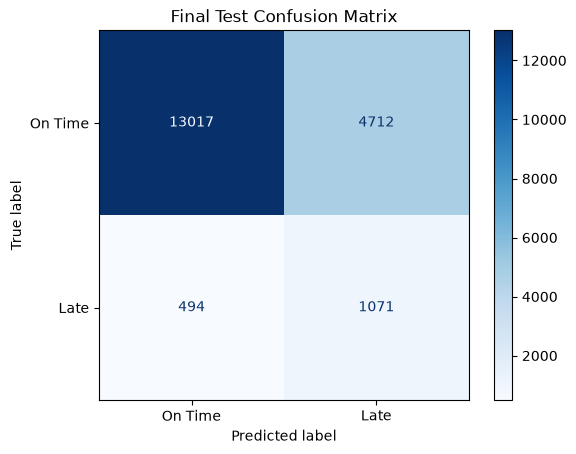

In [14]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt

# Predict on untouched test set
y_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= best_thr).astype(int)

# Evaluation metrics
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_proba), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["On Time", "Late"],
    cmap="Blues"
)
plt.title("Final Test Confusion Matrix")
plt.show()


In [15]:

error_df = X_test.copy()
error_df["actual"] = y_test.to_numpy()
error_df["predicted"] = y_pred
error_df["risk_score"] = y_proba

error_df["error_type"] = np.select(
    [
        (error_df["actual"] == 0) & (error_df["predicted"] == 1),
        (error_df["actual"] == 1) & (error_df["predicted"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

print(error_df["error_type"].value_counts())

print("\nErrors by customer state:")
print(
    error_df.groupby("customer_state")["error_type"]
    .value_counts(normalize=True)
    .unstack(fill_value=0)
    .round(3)
)


error_type
Correct           14088
False Positive     4712
False Negative      494
Name: count, dtype: int64

Errors by customer state:
error_type      Correct  False Negative  False Positive
customer_state                                         
AC                0.833           0.083           0.083
AL                0.378           0.022           0.600
AM                0.828           0.000           0.172
AP                0.938           0.000           0.062
BA                0.529           0.014           0.457
CE                0.580           0.000           0.420
DF                0.656           0.020           0.324
ES                0.566           0.024           0.410
GO                0.661           0.025           0.314
MA                0.504           0.000           0.496
MG                0.800           0.019           0.180
MS                0.551           0.007           0.442
MT                0.726           0.027           0.247
PA                0.650 

### 7.1 Error analysis and operating implications

The test confusion-matrix analysis reports **4,712 false positives** (orders flagged as late that arrived on time) and **494 false negatives** (late orders that the system missed). The model correctly identifies **1,071** late orders.

- **False positives:** Extra alerts may increase manual monitoring costs. The system should not automatically purchase shipping upgrades based on its risk flag.
- **False negatives:** Some customers may still experience unexpected delays even when an order receives a lower-risk classification.
- **Regional variation:** Error rates differ by customer state in the historical test data; comparisons should consider sample sizes and operational context rather than attributing failure to a particular location.

**Recommended use:** Prioritize human follow-up and selective carrier monitoring, then measure the cost of alerts before integrating this system into operational decisions.

### 7.2 Final model performance and interpretation

| Metric | Held-out test result |
|:--|--:|
| Accuracy | **73.02%** |
| Precision (late class) | **18.52%** |
| Recall (late class) | **68.43%** |
| F1-score (late class) | **29.15%** |
| ROC-AUC | **0.7834** |
| PR-AUC | **0.2828** |

**Selected model:** Tuned, class-weighted `HistGradientBoostingClassifier` inside a preprocessing Pipeline. **Tuning CV PR-AUC:** approximately **0.2794**. **Validation-selected alert threshold:** approximately **0.4801**.

**Interpretation:** On this test set, the model identified roughly 68 out of every 100 actually late orders. However, only about 19 out of every 100 flagged orders were late. As a result, the useful application is a **screening and monitoring aid**, not an autonomous operational decision engine.

**Important distinction:** The 70% recall objective was applied on the **validation set**; observed **test recall was 68.43%**. Model scores are **not calibrated probabilities**.

## 8. Model interpretability: permutation importance

Use **permutation importance** on a validation sample, measured as the average drop in PR-AUC after shuffling each feature. This measures how much the fitted model's performance relies on a feature in this evaluation setting; it does **not** establish causality.

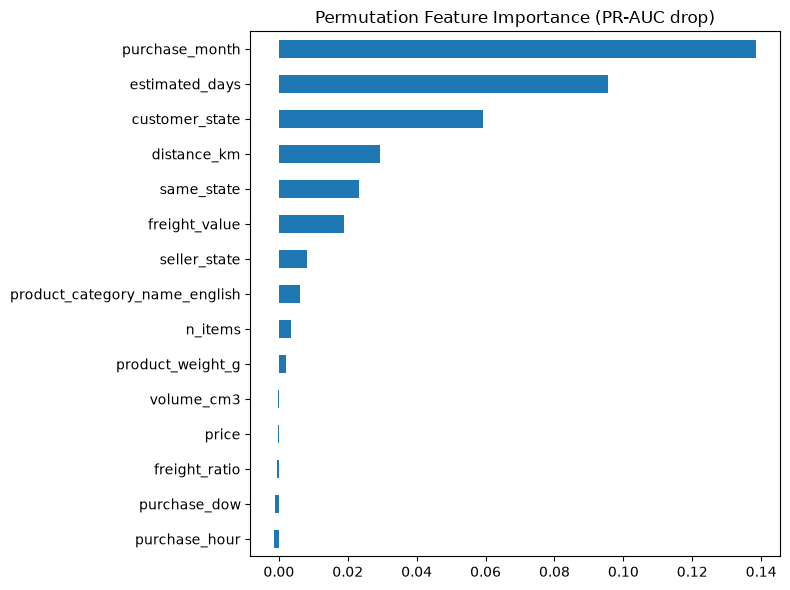

purchase_month                   0.1385
estimated_days                   0.0955
customer_state                   0.0593
distance_km                      0.0294
same_state                       0.0232
freight_value                    0.0188
seller_state                     0.0081
product_category_name_english    0.0061
n_items                          0.0036
product_weight_g                 0.0022
volume_cm3                      -0.0002
price                           -0.0003
freight_ratio                   -0.0007
purchase_dow                    -0.0013
purchase_hour                   -0.0013
dtype: float64


In [16]:

from sklearn.inspection import permutation_importance

sample = X_valid.sample(
    n=min(5000, len(X_valid)),
    random_state=42
)

r = permutation_importance(
    best_model,
    sample,
    y_valid.loc[sample.index],
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

imp = pd.Series(
    r.importances_mean,
    index=sample.columns
).sort_values()

imp.plot(
    kind="barh",
    figsize=(8, 6),
    title="Permutation Feature Importance (PR-AUC drop)"
)

plt.tight_layout()
plt.show()

print(imp.sort_values(ascending=False).round(4))


### 8.1 Feature-importance findings

The validation-based permutation analysis ranks the following predictors highest by PR-AUC decrease:

| Feature | Mean importance (PR-AUC drop) |
|:--|--:|
| `purchase_month` | 0.1385 |
| `estimated_days` | 0.0955 |
| `customer_state` | 0.0593 |
| `distance_km` | 0.0294 |
| `same_state` | 0.0232 |

**Operational insight:** Purchase timing, delivery estimates and customer geography provide the strongest measured predictive signals in this analysis. Shipping distance and whether buyer and seller are in the same state also contribute.

**Interpretation caution:** These are contributions to predictive performance, not evidence that changing a feature will cause delivery to become faster. Correlated features may share information.

## 9. Export the trained pipeline and application data

Save the **fitted preprocessing-and-classification Pipeline**, validation-selected threshold, and model feature lists in `smartship_model.pkl`. Export the seller-level descriptive performance table and ZIP-prefix coordinate/state lookup CSVs used by the Streamlit application.

**Seller statistics:** An order involving multiple sellers can contribute to each participating seller's history. A late order does not by itself establish which seller, if any, caused the delay.

In [17]:
import joblib

# Save the full fitted Pipeline and the validation-only decision threshold.
# Only load this file from a project you trust (joblib/pickle are executable formats).
model_bundle = {
    "model": best_model,
    "threshold": float(best_thr),
    "num_features": list(num_features),
    "cat_features": list(cat_features),
}
output_model = PROJECT_DIR / "smartship_model.pkl"
joblib.dump(model_bundle, output_model)
print("Model saved to:", output_model)
print("Decision threshold:", round(best_thr, 4))

Model saved to: c:\Users\Administrator\Desktop\SmartShip-AI\smartship_model.pkl
Decision threshold: 0.4801


In [18]:

seller_orders = items[["order_id", "seller_id"]].drop_duplicates()

seller_orders = seller_orders.merge(
    delivered[["order_id", "is_late"]],
    on="order_id",
    how="inner"
)

seller_orders = seller_orders.merge(
    sellers[["seller_id", "seller_state"]],
    on="seller_id",
    how="left"
)

seller_stats = (
    seller_orders.groupby("seller_id")
    .agg(
        orders=("order_id", "nunique"),
        late_rate=("is_late", "mean"),
        state=("seller_state", "first")
    )
    .reset_index()
)

seller_stats.to_csv("data/seller_stats.csv", index=False)

print("Seller statistics saved successfully!")


Seller statistics saved successfully!


In [19]:
# Geography exports used by the Streamlit order form.
# Prefix values are numeric IDs; display as five digits using str(prefix).zfill(5).
zip_centroids = (
    geo.groupby("geolocation_zip_code_prefix", as_index=False)
       .agg(lat=("geolocation_lat", "mean"),
            lng=("geolocation_lng", "mean"))
)
zip_states = (
    geo.groupby("geolocation_zip_code_prefix", as_index=False)
       .agg(state=("geolocation_state", lambda x: x.mode().iloc[0]))
)
zip_centroids.to_csv(PROJECT_DIR / "data" / "zip_centroids.csv", index=False)
zip_states.to_csv(PROJECT_DIR / "data" / "zip_states.csv", index=False)
print(f"Exported {len(zip_centroids):,} ZIP prefix coordinates and {len(zip_states):,} state mappings")

sample_sp = zip_states.loc[zip_states["state"] == "SP", "geolocation_zip_code_prefix"].head(10)
print("Example SP prefixes:", [str(v).zfill(5) for v in sample_sp])

Exported 19,015 ZIP prefix coordinates and 19,015 state mappings
Example SP prefixes: ['01001', '01002', '01003', '01004', '01005', '01006', '01007', '01008', '01009', '01010']


## 10. Artifact verification

Reload the serialized model bundle and check the existence of the supporting CSV files. This confirms that the expected artifacts were produced; it does **not** replace an end-to-end test of the deployed Streamlit application.

In [20]:
saved_bundle = joblib.load(PROJECT_DIR / "smartship_model.pkl")
assert set(saved_bundle) == {"model", "threshold", "num_features", "cat_features"}
assert saved_bundle["num_features"] == num_features
assert saved_bundle["cat_features"] == cat_features
print("Saved threshold:", round(saved_bundle["threshold"], 4))
print("Saved model:", type(saved_bundle["model"]).__name__)
print("Seller stats:", (PROJECT_DIR / "data" / "seller_stats.csv").exists())
print("ZIP centroids:", (PROJECT_DIR / "data" / "zip_centroids.csv").exists())
print("ZIP states:", (PROJECT_DIR / "data" / "zip_states.csv").exists())

Saved threshold: 0.4801
Saved model: Pipeline
Seller stats: True
ZIP centroids: True
ZIP states: True


## 11. Business insights, recommendations and limitations

### Findings

- **Risk varies by location and time.** Historical EDA and permutation importance both point to geographic and seasonal differences, although neither proves causation.
- **Early warnings can catch many late orders.** Test recall is **68.43%**; however, test precision is **18.52%**, so false alerts are a major operating consideration.
- **Seller histories vary.** Some sellers with at least 30 associated orders show observed late rates around **27–35%**. For context, the overall delivered-order late rate in the modeling data was about **8.11%**; the seller-order weighted rate displayed in the app is about **8.0%**. These measures have different counting bases and should not be treated as identical.

### Recommendations

1. **Use risk flags for triage:** Prioritize customer communication and carrier monitoring for elevated-risk orders, rather than automatic paid shipment changes.
2. **Review shipping patterns:** Examine cross-state, long-distance and historically higher-risk periods when planning operational follow-up.
3. **Monitor seller-associated late rates:** Consider each seller's order volume, routes and operating conditions before escalating concerns.
4. **Assess delivery promises:** Investigate whether particular routes need more realistic estimated delivery windows.

### Limitations

- **False alerts and missed delays:** Low precision makes alert costs important, and the model still misses some late orders.
- **Historical coverage:** The Olist data cover **2016–2018**; performance on current orders has not been demonstrated.
- **Evaluation design:** A random holdout does not simulate future chronological deployment. The alert threshold was selected on validation data, not the test set.
- **Uncalibrated scores:** Output values are model scores, **not reliable calibrated probabilities**.
- **Population coverage:** Only delivered orders with the relevant dates were modeled; canceled and other undelivered orders are outside the evaluated scope.
- **Geographic approximation:** ZIP-prefix centroids and Haversine distances estimate straight-line separation, not actual road distances; some coordinates may be missing or imperfect.
- **Order representation:** For multi-product or multi-seller orders, some product and seller inputs are representative rather than exhaustive. Seller-associated delays are not proof of seller fault.

## 12. Conclusion and deliverables

### Conclusion

This project demonstrates an end-to-end classical machine-learning workflow for **late-delivery risk assessment** on real Olist marketplace data: relational joins, feature engineering, exploratory analysis, leakage-aware Pipelines, a baseline and three model families, cross-validation, tuning, threshold selection and held-out evaluation.

The selected **HistGradientBoosting Pipeline** achieved **0.2828 PR-AUC**, **0.7834 ROC-AUC** and **68.43% recall** on the held-out test set, with **18.52% precision**. The evidence supports use as a **human-supervised early-warning prototype**: it identifies many potential delays, but false alerts must be managed carefully.

### Project artifacts

- **`smartship.ipynb`** — reproducible analysis, modeling, evaluation and interpretations.
- **`smartship_model.pkl`** — saved fitted Pipeline, alert threshold and feature lists.
- **`app.py`** — Streamlit order-risk form and historical seller-performance dashboard.
- **Supporting files in `data/`** — seller summary and ZIP-prefix lookup tables used by the app.
- **`README.md`** — should document the dataset source, metrics, installation, screenshots and public application link when deployment is complete.
- **Presentation and project demo** — prepared separately for final submission, together with the required GitHub and live-app links.

**Source:** [Olist Brazilian E-Commerce Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). **Scope:** Findings and performance estimates are historical; reliable deployment requires monitoring and re-evaluation on current data.